In [1]:
# 1. Import libraries and basic settings
import json, re, os, datetime
from collections import Counter
from difflib import get_close_matches
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
os.makedirs("figures", exist_ok=True)       # plots will be saved here
TODAY = datetime.date(2026, 10, 17)         # "today" used when the order data was made

In [2]:
# 2. Load the data (all files must be in the same folder as this notebook)
catalog = pd.read_csv("catalog.csv", dtype={"size": str})   # size stays text (M, 32, 2-3Y, Free)
orders = pd.read_csv("orders.csv", dtype=str)
policy_text = open("policy.md", encoding="utf-8").read()
rules = json.load(open("policy_rules.json", encoding="utf-8"))
conversations = json.load(open("conversations.json", encoding="utf-8"))["conversations"]

print("catalog rows       :", len(catalog))
print("orders             :", len(orders))
print("policy words       :", len(policy_text.split()))
print("conversations      :", len(conversations))
catalog.head()

catalog rows       : 572
orders             : 51
policy words       : 1313
conversations      : 172


,sku,product_id,name,category,color,size,original_price,price,stock,is_sale,description
0,SKU0001,P001,Linen Kurta,Men Kurta,Black,S,2499,2499,5,False,"Breathable pure linen kurta, straight cut, ide..."
1,SKU0002,P001,Linen Kurta,Men Kurta,Black,M,2499,2499,12,False,"Breathable pure linen kurta, straight cut, ide..."
2,SKU0003,P001,Linen Kurta,Men Kurta,Black,L,2499,2499,1,False,"Breathable pure linen kurta, straight cut, ide..."
3,SKU0004,P001,Linen Kurta,Men Kurta,Black,XL,2499,2499,22,False,"Breathable pure linen kurta, straight cut, ide..."
4,SKU0005,P001,Linen Kurta,Men Kurta,White,S,2499,2499,0,False,"Breathable pure linen kurta, straight cut, ide..."


In [3]:
# 3. Quality checks on the catalog (before cleaning)
def catalog_checks(df):
    return pd.Series({
        "rows": len(df),
        "missing values": df.isna().sum().sum(),
        "duplicate SKUs": df["sku"].duplicated().sum(),
        "duplicate variants": df.duplicated(["product_id", "color", "size"]).sum(),
        "negative stock": (df["stock"] < 0).sum(),
        "price <= 0": (df["price"] <= 0).sum(),
        "sale price not below original": ((df["is_sale"] == True) & (df["price"] >= df["original_price"])).sum(),
        "extra spaces in color/size": (df["color"] != df["color"].str.strip()).sum() + (df["size"] != df["size"].str.strip()).sum(),
    })

before = catalog_checks(catalog)
print(before)

rows                             572
missing values                     0
duplicate SKUs                     0
duplicate variants                 0
negative stock                     0
price <= 0                         0
sale price not below original      0
extra spaces in color/size         0
dtype: int64


In [4]:
# 4. Clean the catalog and add useful columns
catalog["name"] = catalog["name"].str.strip()
catalog["color"] = catalog["color"].str.strip().str.title()
catalog["size"] = catalog["size"].str.strip().str.upper().replace({"FREE": "Free"})

catalog["discount_pct"] = ((1 - catalog["price"] / catalog["original_price"]) * 100).round().astype(int)

def stock_status(n):
    if n == 0:
        return "out_of_stock"
    elif n < 5:
        return "low_stock"
    return "in_stock"
catalog["stock_status"] = catalog["stock"].apply(stock_status)

after = catalog_checks(catalog)
print(pd.DataFrame({"before": before, "after": after}))
catalog.head(3)

                               before  after
rows                              572    572
missing values                      0      0
duplicate SKUs                      0      0
duplicate variants                  0      0
negative stock                      0      0
price <= 0                          0      0
sale price not below original       0      0
extra spaces in color/size          0      0


,sku,product_id,name,category,color,size,original_price,price,stock,is_sale,description,discount_pct,stock_status
0,SKU0001,P001,Linen Kurta,Men Kurta,Black,S,2499,2499,5,False,"Breathable pure linen kurta, straight cut, ide...",0,in_stock
1,SKU0002,P001,Linen Kurta,Men Kurta,Black,M,2499,2499,12,False,"Breathable pure linen kurta, straight cut, ide...",0,in_stock
2,SKU0003,P001,Linen Kurta,Men Kurta,Black,L,2499,2499,1,False,"Breathable pure linen kurta, straight cut, ide...",0,low_stock


In [5]:
# 5. Synonym table: different ways customers write colors, sizes and products
color_words = {"black": ["blk", "kala", "blak"], "white": ["safaid", "wht", "safed"], "navy": ["navy blue", "navi"],
               "grey": ["gray", "slate"], "maroon": ["marun"], "pink": ["gulabi"], "green": ["sabz"],
               "sky blue": ["asmani"], "red": ["laal"], "blue": ["nila"]}
size_words = {"S": ["s", "small", "smll"], "M": ["m", "medium", "mdm", "meedium"],
              "L": ["l", "large", "lrg"], "XL": ["xl", "extra large", "xxl"]}
product_words = {"Polo T-Shirt": ["polo tshirt"], "Graphic T-Shirt": ["graphic tshirt"],
                 "Wash & Wear Kurta": ["wash n wear kurta", "wash and wear kurta"], "Lawn 3-Piece Stitched": ["lawn 3 piece"],
                 "Denim Jeans Slim Fit": ["slim fit jeans", "jeans"], "Chiffon Party Wear": ["chiffon party suit"],
                 "Hijab Chiffon": ["chiffon hijab"]}

# every color in the catalog is also a valid word for itself
for c in catalog["color"].str.lower().unique():
    color_words.setdefault(c, [])
    if c not in color_words[c]:
        color_words[c].append(c)

rows = []
for name, words in color_words.items():
    for w in words: rows.append(("color", name, w))
for name, words in size_words.items():
    for w in words: rows.append(("size", name, w))
for name, words in product_words.items():
    for w in words: rows.append(("product", name, w))
synonyms = pd.DataFrame(rows, columns=["type", "canonical", "alias"]).drop_duplicates()
print(synonyms["type"].value_counts().to_dict())

alias_to_color = {w: name for name, words in color_words.items() for w in words}
alias_to_size = {w: name for name, words in size_words.items() for w in words}

def match_color(word):
    """Map a customer word to a catalog color. Handles small spelling mistakes."""
    if word in alias_to_color:
        return alias_to_color[word]
    close = get_close_matches(word, list(alias_to_color), n=1, cutoff=0.8)
    return alias_to_color[close[0]] if close else None

for w in ["blk", "kala", "blak", "safaid", "gulabi", "marun", "navi", "kurta", "hai"]:
    print(w, "->", match_color(w))

{'color': 47, 'size': 13, 'product': 9}
blk -> black
kala -> black
blak -> black
safaid -> white
gulabi -> pink
marun -> maroon
navi -> navy
kurta -> None
hai -> None


In [6]:
# 6. Clean the customer messages (Roman Urdu / English text)
def clean_text(text):
    text = text.lower().strip()
    text = re.sub(r"\b(03\d{2})[-\s](\d{7})\b", r"\1\2", text)   # 0300-1234567 -> 03001234567
    text = re.sub(r"[\u200b\U0001F300-\U0001FAFF]", "", text)       # remove emojis
    text = re.sub(r"\s+", " ", text)                                # extra spaces and new lines
    return text.strip()

for conv in conversations:
    for turn in conv["turns"]:
        turn["text_clean"] = clean_text(turn["text"])

changed = sum(any(t["text"] != t["text_clean"] for t in c["turns"]) for c in conversations)
print("conversations changed by cleaning:", changed, "of", len(conversations))
print("before:", conversations[6]["turns"][2]["text"])
print("after :", conversations[6]["turns"][2]["text_clean"])

conversations changed by cleaning: 117 of 172
before: Mera naam Ali Raza hai, 03001234567, house 12 street 4 Model Town Lahore
after : mera naam ali raza hai, 03001234567, house 12 street 4 model town lahore


In [7]:
# 7. Check the conversation labels
valid_actions = {"check_stock", "recommend", "answer_policy", "create_order", "request_confirmation", "request_missing_info",
                 "get_order_status", "deny_status_mismatch", "create_exchange", "escalate"}
catalog_keys = set(catalog["name"] + "|" + catalog["color"] + "|" + catalog["size"])
order_ids = set(orders["order_id"])

problems = []
for c in conversations:
    exp = c["expected"]
    cid = c["conv_id"]
    if exp["expected_action"] not in valid_actions:
        problems.append((cid, "invalid action"))
    if exp["should_escalate"] != (exp["expected_action"] == "escalate"):
        problems.append((cid, "escalate flag does not match action"))
    if any(t["text_clean"] == "" for t in c["turns"]):
        problems.append((cid, "empty message"))
    for item in exp["entities"]["items"]:
        if item["color"] and item["size"] and f"{item['product']}|{item['color']}|{item['size']}" not in catalog_keys:
            problems.append((cid, "item not in catalog"))
    oid = exp["entities"]["order_id"]
    if oid and oid not in order_ids and exp["escalation_reason"] != "order_not_found":
        problems.append((cid, "unknown order id"))

all_texts = [" | ".join(t["text_clean"] for t in c["turns"]) for c in conversations]
print("label problems:", len(problems))
print("duplicate conversations:", len(all_texts) - len(set(all_texts)))

label problems: 0
duplicate conversations: 0


In [8]:
# 8. Can cleaning + fuzzy matching find the labeled color and size in the text?
# (Only a consistency check. The conversations were made with the same word list, so this is not real accuracy.)
def find_colors(text):
    words = re.findall(r"[a-z]+", text)
    found = set()
    for i, w in enumerate(words):
        if len(w) < 3:
            continue
        if i + 1 < len(words) and (w + " " + words[i + 1]) in alias_to_color:    # two-word colors like "sky blue"
            found.add(alias_to_color[w + " " + words[i + 1]])
        elif match_color(w):
            found.add(match_color(w))
    return found

def find_sizes(text):
    text = text.replace("extra large", "xl")
    found = {alias_to_size[w] for w in re.findall(r"[a-z]+", text) if w in alias_to_size}
    found |= set(re.findall(r"\b(\d{1,2}-\dY|\d{2})\b", text.upper()))        # 32, 2-3Y
    found |= set(re.findall(r"SIZE (\d)\b", text.upper()))                       # size 8
    return found

color_ok = color_total = size_ok = size_total = 0
for c in conversations:
    text = " ".join(t["text_clean"] for t in c["turns"])
    colors, sizes = find_colors(text), find_sizes(text)
    for item in c["expected"]["entities"]["items"]:
        if item["color"] and c["category"] != "exchange":   # in exchange chats the color comes from the order, not the text
            color_total += 1
            color_ok += item["color"].lower() in colors
        if item["size"] and item["size"] != "Free":
            size_total += 1
            size_ok += item["size"].upper() in sizes
print(f"color found: {color_ok}/{color_total}")
print(f"size found : {size_ok}/{size_total}")

color found: 79/79
size found : 94/94


In [9]:
# 9. Split the policy document into chunks (for RAG)
def chunk_policy(text, max_words=250):
    chunks = []
    for section in re.split(r"\n(?=## )", text):
        lines = [l for l in section.strip().split("\n") if l.strip()]
        if not lines or not lines[0].startswith("## "):
            continue
        title, body = lines[0][3:].strip(), lines[1:]
        current, count = [], 0
        for line in body:
            words = len(line.split())
            if current and count + words > max_words:      # chunk is full, start a new one
                chunks.append((title, current, count))
                current, count = [], 0
            current.append(line)
            count += words
        if current:
            chunks.append((title, current, count))
    return [{"chunk_id": f"P{i:02d}", "section": t, "text": t + "\n" + "\n".join(lines), "n_words": n}
            for i, (t, lines, n) in enumerate(chunks, 1)]

policy_chunks = chunk_policy(policy_text)
chunk_df = pd.DataFrame(policy_chunks)
print(len(chunk_df), "chunks, average", round(chunk_df["n_words"].mean()), "words")
chunk_df[["chunk_id", "section", "n_words"]]

10 chunks, average 121 words


,chunk_id,section,n_words
0,P01,1. Business Information,75
1,P02,2. Delivery Areas and Charges,107
2,P03,3. Payment (COD),82
3,P04,4. Placing an Order,148
4,P05,5. Order Status,79
5,P06,6. Exchange Policy,196
6,P07,7. Returns and Refunds,88
7,P08,8. Cases the AI Must Hand Over to a Human,165
8,P09,9. General Rules for the AI Assistant,82
9,P10,10. Frequently Asked Questions (Roman Urdu / E...,192


In [10]:
# 10. Clean the orders table and save all cleaned files
orders["qty"] = orders["qty"].astype(int)
orders["total"] = orders["total"].astype(int)
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders["delivered_date"] = pd.to_datetime(orders["delivered_date"])

catalog.to_csv("catalog_clean.csv", index=False)
orders.to_csv("orders_clean.csv", index=False)
synonyms.to_csv("synonyms.csv", index=False)
json.dump(policy_chunks, open("policy_chunks.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
json.dump(conversations, open("conversations_clean.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("saved: catalog_clean.csv, orders_clean.csv, synonyms.csv, policy_chunks.json, conversations_clean.json")

saved: catalog_clean.csv, orders_clean.csv, synonyms.csv, policy_chunks.json, conversations_clean.json


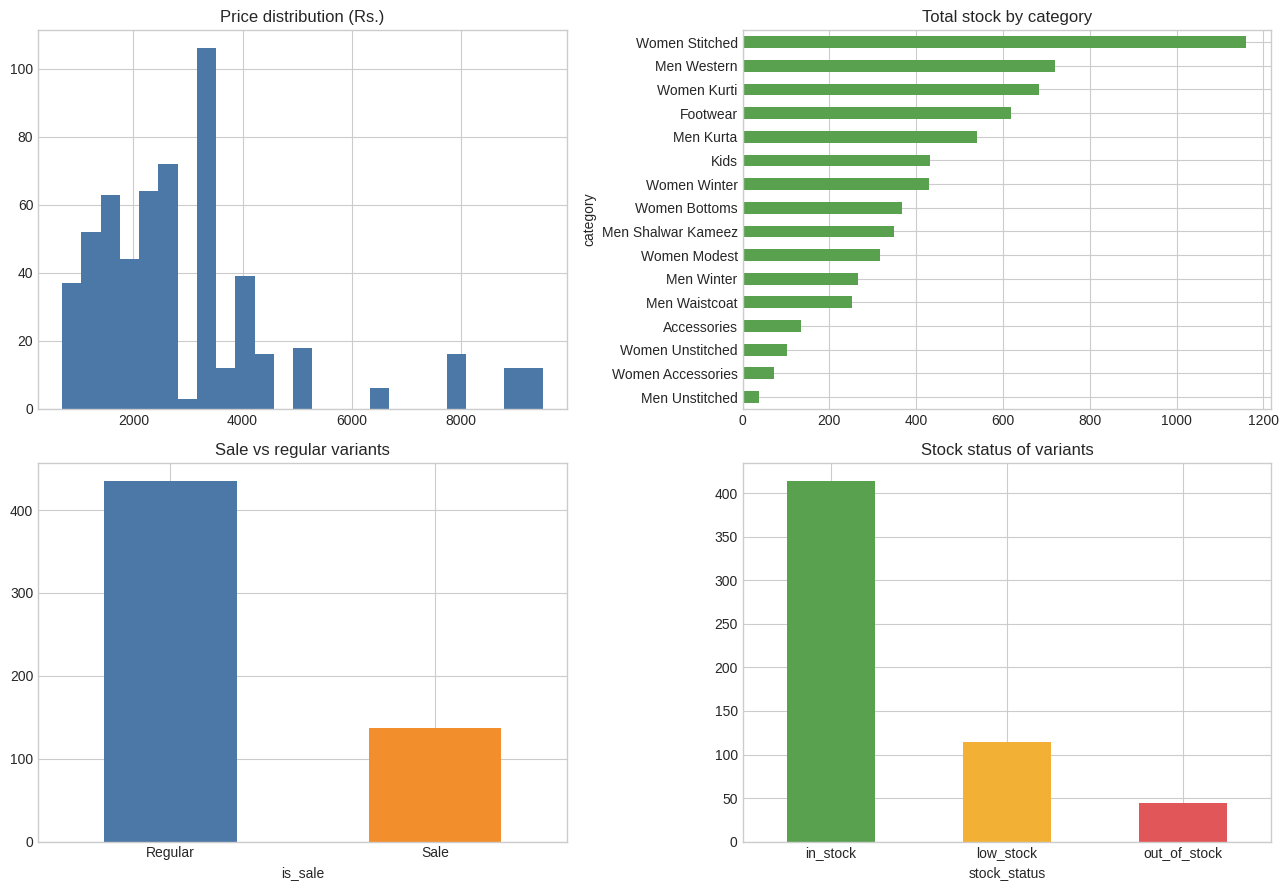

Insight: 572 variants of 50 products, median price Rs. 2499.
8% of variants are out of stock and 20% are low stock (under 5).
24% of variants are on sale (these cannot be exchanged).


In [11]:
# 11. EDA - catalog
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].hist(catalog["price"], bins=25, color="#4C78A8")
ax[0, 0].set_title("Price distribution (Rs.)")
catalog.groupby("category")["stock"].sum().sort_values().plot.barh(ax=ax[0, 1], color="#59A14F")
ax[0, 1].set_title("Total stock by category")
catalog["is_sale"].map({True: "Sale", False: "Regular"}).value_counts().plot.bar(ax=ax[1, 0], color=["#4C78A8", "#F28E2B"], rot=0)
ax[1, 0].set_title("Sale vs regular variants")
catalog["stock_status"].value_counts().reindex(["in_stock", "low_stock", "out_of_stock"]).plot.bar(
    ax=ax[1, 1], color=["#59A14F", "#F2B134", "#E15759"], rot=0)
ax[1, 1].set_title("Stock status of variants")
plt.tight_layout()
plt.savefig("figures/eda_catalog.png", dpi=150, bbox_inches="tight")
plt.show()

share = catalog["stock_status"].value_counts(normalize=True)
print(f"Insight: {len(catalog)} variants of {catalog['product_id'].nunique()} products, median price Rs. {catalog['price'].median():.0f}.")
print(f"{share['out_of_stock']:.0%} of variants are out of stock and {share['low_stock']:.0%} are low stock (under 5).")
print(f"{catalog['is_sale'].mean():.0%} of variants are on sale (these cannot be exchanged).")

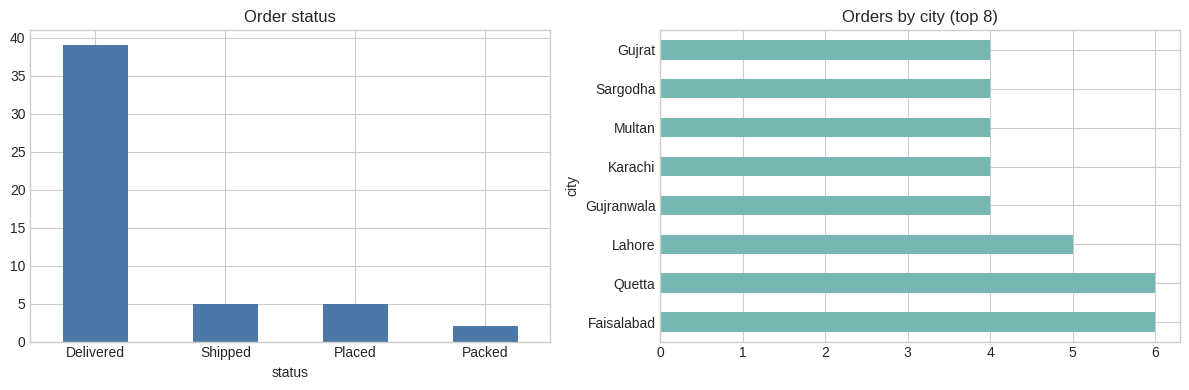

Insight: 51 orders, 76% delivered.
Of the delivered orders, 35 are inside the 7-day exchange window and 4 are outside.


In [12]:
# 12. EDA - orders
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
orders["status"].value_counts().plot.bar(ax=ax[0], color="#4C78A8", rot=0)
ax[0].set_title("Order status")
orders["city"].value_counts().head(8).plot.barh(ax=ax[1], color="#76B7B2")
ax[1].set_title("Orders by city (top 8)")
plt.tight_layout()
plt.savefig("figures/eda_orders.png", dpi=150, bbox_inches="tight")
plt.show()

days = (pd.Timestamp(TODAY) - orders["delivered_date"].dropna()).dt.days
print(f"Insight: {len(orders)} orders, {(orders['status'] == 'Delivered').mean():.0%} delivered.")
print(f"Of the delivered orders, {(days <= 7).sum()} are inside the 7-day exchange window and {(days > 7).sum()} are outside.")

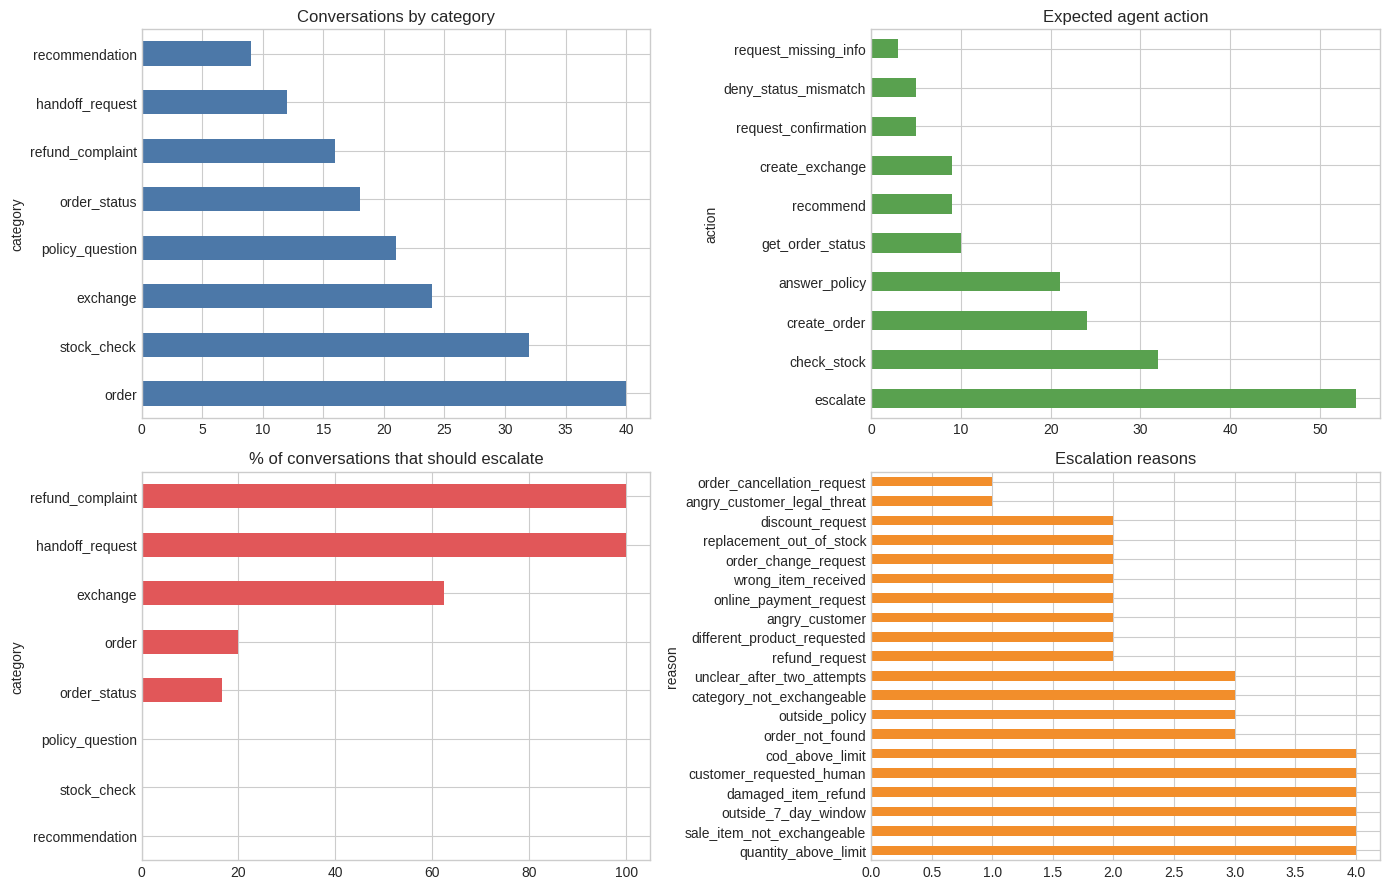

Insight: 172 conversations in 8 categories.
31% should escalate, so a system that never escalates scores at most 69% on action.
Biggest categories: order, stock_check, exchange. Smallest: recommendation (9).


In [13]:
# 13. EDA - conversations (categories, actions, escalation)
rows = []
for c in conversations:
    rows.append({"conv_id": c["conv_id"], "source": c["source"], "split": c["split"], "category": c["category"],
                 "difficulty": c["difficulty"], "action": c["expected"]["expected_action"],
                 "escalate": c["expected"]["should_escalate"], "reason": c["expected"]["escalation_reason"],
                 "n_turns": len(c["turns"]), "tags": c["tags"],
                 "n_words": sum(len(t["text_clean"].split()) for t in c["turns"])})
cdf = pd.DataFrame(rows)

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
cdf["category"].value_counts().plot.barh(ax=ax[0, 0], color="#4C78A8")
ax[0, 0].set_title("Conversations by category")
cdf["action"].value_counts().plot.barh(ax=ax[0, 1], color="#59A14F")
ax[0, 1].set_title("Expected agent action")
(cdf.groupby("category")["escalate"].mean() * 100).sort_values().plot.barh(ax=ax[1, 0], color="#E15759")
ax[1, 0].set_title("% of conversations that should escalate")
cdf["reason"].value_counts().plot.barh(ax=ax[1, 1], color="#F28E2B")
ax[1, 1].set_title("Escalation reasons")
plt.tight_layout()
plt.savefig("figures/eda_conversations.png", dpi=150, bbox_inches="tight")
plt.show()

counts = cdf["category"].value_counts()
print(f"Insight: {len(cdf)} conversations in {len(counts)} categories.")
print(f"{cdf['escalate'].mean():.0%} should escalate, so a system that never escalates scores at most {1 - cdf['escalate'].mean():.0%} on action.")
print(f"Biggest categories: {', '.join(counts.index[:3])}. Smallest: {counts.index[-1]} ({counts.iloc[-1]}).")

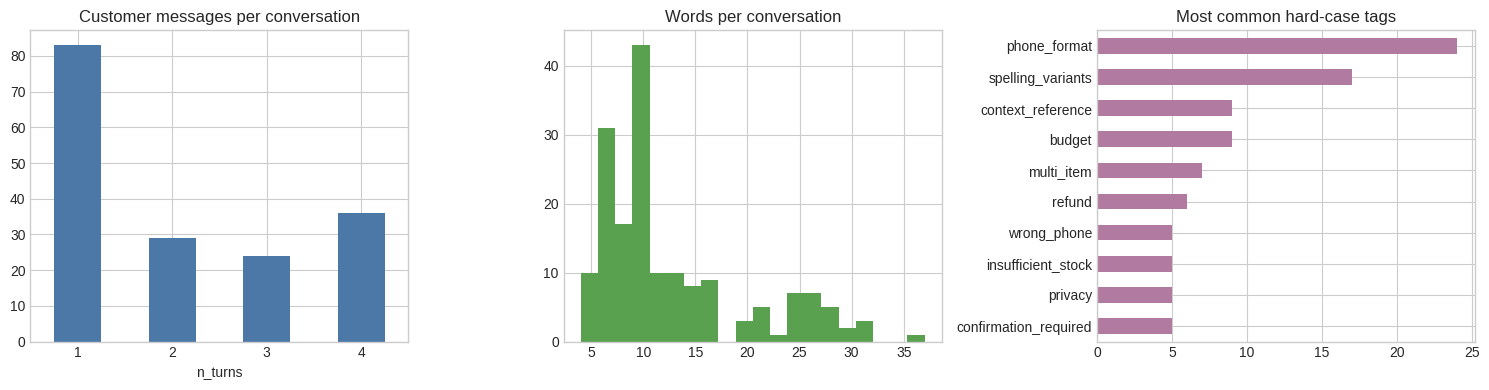

Insight: on average 2.1 customer messages and 13 words per conversation.
63% are hard cases and 52% are multi-turn.


In [14]:
# 14. EDA - length and difficulty
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
cdf["n_turns"].value_counts().sort_index().plot.bar(ax=ax[0], color="#4C78A8", rot=0)
ax[0].set_title("Customer messages per conversation")
ax[1].hist(cdf["n_words"], bins=20, color="#59A14F")
ax[1].set_title("Words per conversation")
tag_counts = Counter(t for tags in cdf["tags"] for t in tags if t != "multi_turn")
pd.Series(tag_counts).sort_values().tail(10).plot.barh(ax=ax[2], color="#B07AA1")
ax[2].set_title("Most common hard-case tags")
plt.tight_layout()
plt.savefig("figures/eda_length_difficulty.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Insight: on average {cdf['n_turns'].mean():.1f} customer messages and {cdf['n_words'].mean():.0f} words per conversation.")
print(f"{(cdf['difficulty'] == 'hard').mean():.0%} are hard cases and {(cdf['n_turns'] > 1).mean():.0%} are multi-turn.")

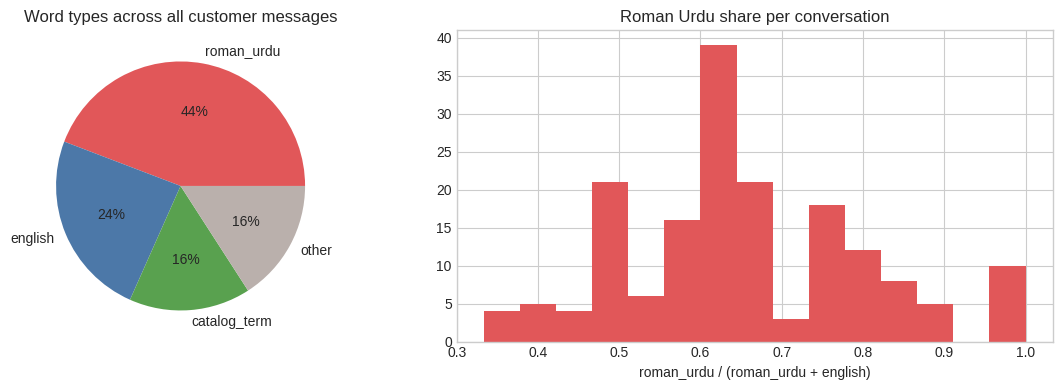

Insight: 94% of conversations contain both Roman Urdu and English words.
About 65% of the language words (without product terms) are Roman Urdu.


In [15]:
# 15. EDA - code-mixing (Roman Urdu vs English), simple word-list method
urdu_words = set("""hai hain mein main me ka ki ke ko se par pe aur ya kya kitna kitne kitni kab kahan kyun chahiye chahta chahti karo kar karna
karni do dena de bhej bhejo bhejna batao bata dikhao dikha nahi nahin haan ji jee acha theek sahi bhai mera meri mere mujhe aap ap apka
tum wo woh ye yeh ab abhi bohat bahut zyada kam thora thoda mil milega milta hota hoti hoga ho tak jagah din paise wapis kal aaj pehle
baad naam jootay kapre bachon insan baat banda kharab phata phat gaya gayi hua hui nikla bheja diya mangwaya tha thi wala wali jo liya
lun karun karungi karunga jaunga jati jata aya aye aaya pohancha pohanchay pohanchega lagenge lagega bhi hi koi kuch sab sirf wahi
bakwas bura khuli kala safaid gulabi sabz asmani laal marun salam assalam alaikum shukriya mehngi sasta pasand dekhna dekh dekhne aao
aa sakte sakta sakti hun hoon hu kaun kon yaar arre suno pata raha rahe rahi chota bara chhota thik jaldi bas wapas lo lena dedo dijiye
please""".split())
english_words = set("""available stock price order size color colour delivery charges charge cod exchange policy status confirm yes done free rate
discount last refund return cancel change address phone number name house street hello hi manager owner human payment advance transfer
account parcel complaint court case service experience late fraud custom stitching gift wrapping message card the is are for with and
small medium large extra shop pieces piece bulk budget around suggest show send same cash on bank hours staff reply fit tight shrink wash
showroom dubai fia wholesale rs""".split())
catalog_words = set(re.findall(r"[a-z]+", " ".join(catalog["name"].str.lower().tolist() + catalog["color"].str.lower().tolist())))

def word_type(w):
    if w in urdu_words: return "roman_urdu"
    if w in english_words: return "english"
    if w in catalog_words: return "catalog_term"
    return "other"

rows = []
for c in conversations:
    words = re.findall(r"[a-z]+", " ".join(t["text_clean"] for t in c["turns"]))
    cnt = Counter(word_type(w) for w in words)
    rows.append({"roman_urdu": cnt["roman_urdu"], "english": cnt["english"], "catalog_term": cnt["catalog_term"], "other": cnt["other"]})
mix = pd.DataFrame(rows)
mix["urdu_share"] = mix["roman_urdu"] / (mix["roman_urdu"] + mix["english"]).replace(0, float("nan"))
mixed = ((mix["roman_urdu"] > 0) & (mix["english"] > 0)).mean()
totals = mix[["roman_urdu", "english", "catalog_term", "other"]].sum()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
totals.plot.pie(ax=ax[0], autopct="%1.0f%%", colors=["#E15759", "#4C78A8", "#59A14F", "#BAB0AC"], ylabel="")
ax[0].set_title("Word types across all customer messages")
ax[1].hist(mix["urdu_share"].dropna(), bins=15, color="#E15759")
ax[1].set_title("Roman Urdu share per conversation")
ax[1].set_xlabel("roman_urdu / (roman_urdu + english)")
plt.tight_layout()
plt.savefig("figures/eda_code_mixing.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Insight: {mixed:.0%} of conversations contain both Roman Urdu and English words.")
print(f"About {totals['roman_urdu'] / (totals['roman_urdu'] + totals['english']):.0%} of the language words (without product terms) are Roman Urdu.")

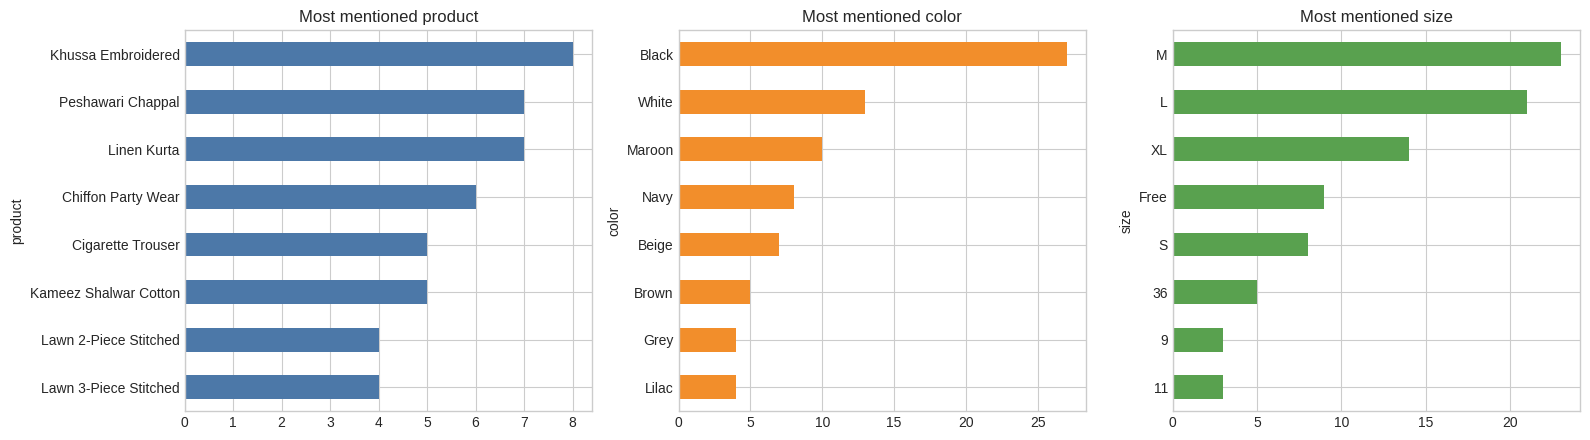

Insight: 104 product mentions. Top product: Khussa Embroidered, top color: Black, top size: M.
41 of 50 catalog products appear in conversations.


In [16]:
# 16. EDA - what customers ask about
items = [item for c in conversations for item in c["expected"]["entities"]["items"]]
items_df = pd.DataFrame(items)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col, color in zip(ax, ["product", "color", "size"], ["#4C78A8", "#F28E2B", "#59A14F"]):
    items_df[col].dropna().value_counts().head(8).sort_values().plot.barh(ax=a, color=color)
    a.set_title(f"Most mentioned {col}")
plt.tight_layout()
plt.savefig("figures/eda_entities.png", dpi=150, bbox_inches="tight")
plt.show()

used = items_df["product"].nunique()
print(f"Insight: {len(items_df)} product mentions. Top product: {items_df['product'].value_counts().index[0]}, "
      f"top color: {items_df['color'].value_counts().index[0]}, top size: {items_df['size'].value_counts().index[0]}.")
print(f"{used} of {catalog['name'].nunique()} catalog products appear in conversations.")

In [17]:
# 17. Final dataset summary
summary = pd.DataFrame([
    ["catalog_clean.csv", "product variants", len(catalog), catalog.shape[1]],
    ["orders_clean.csv", "mock orders", len(orders), orders.shape[1]],
    ["policy_chunks.json", "policy text chunks (RAG)", len(policy_chunks), 4],
    ["policy_rules.json", "rule groups (guardrails)", len([k for k in rules if not k.startswith("_")]), "-"],
    ["conversations_clean.json", "labeled conversations", len(conversations), "turns + 7 label fields"],
    ["synonyms.csv", "color/size/product aliases", len(synonyms), 3],
], columns=["file", "contents", "rows", "columns"])
print(summary.to_string(index=False))

print("\nTrain/test split by category:")
split = pd.crosstab(cdf["category"], cdf["split"], margins=True)
print(split)
print("\nSource:", cdf["source"].value_counts().to_dict())
print("Difficulty:", cdf["difficulty"].value_counts().to_dict())

                    file                   contents  rows                columns
       catalog_clean.csv           product variants   572                     13
        orders_clean.csv                mock orders    51                     12
      policy_chunks.json   policy text chunks (RAG)    10                      4
       policy_rules.json   rule groups (guardrails)     8                      -
conversations_clean.json      labeled conversations   172 turns + 7 label fields
            synonyms.csv color/size/product aliases    69                      3

Train/test split by category:
split             dev  test  All
category                        
exchange           17     7   24
handoff_request     8     4   12
order              28    12   40
order_status       13     5   18
policy_question    15     6   21
recommendation      6     3    9
refund_complaint   11     5   16
stock_check        22    10   32
All               120    52  172

Source: {'template_generated': 152, 'h